# EDA — SQuAD v1.1 (validation)

Analiza exploratorie a datelor pe care se evalueaza toate modelele (baseline, reader, retriever).

Ce urmarim:
1. lungimea pasajelor, intrebarilor si raspunsurilor (tokenizare NLTK)
2. cate perechi intrebare+pasaj depasesc limita BERT de 384 tokeni (justifica sliding window)
3. tipurile de intrebari (what / who / when ...)
4. tipul entitatii din raspuns (spaCy NER) si legatura cu tipul intrebarii (baza regulilor din baseline)
5. pozitia raspunsului in pasaj (in a cata propozitie apare)
6. structura corpusului pentru retriever (paragrafe per articol)

Figurile se salveaza in `docs/figures/`.

In [1]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

import datasets
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import spacy
from matplotlib.colors import LinearSegmentedColormap
from nltk.tokenize import PunktTokenizer, word_tokenize
from transformers import AutoTokenizer

from src.qa.data import build_corpus, group_by_article, load_squad
from src.qa.preprocess import question_type, span_entity_label

datasets.disable_progress_bars()
nltk.download("punkt_tab", quiet=True)

SEED = 42
SPLIT = "validation"
CACHE_DIR = "data/hf_cache"
FIG_DIR = Path("docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
MAX_LENGTH = 384

In [2]:
BLUE = "#2a78d6"
INK = "#0b0b0b"
INK_MUTED = "#52514e"
SURFACE = "#fcfcfb"
GRID = "#e5e4df"
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "blue_seq", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"]
)

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_MUTED,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "font.size": 10,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})


def save(fig, name):
    fig.savefig(FIG_DIR / name)
    plt.show()


def hbar(ax, counts, total):
    ax.barh(counts.index[::-1], counts.values[::-1], color=BLUE, height=0.7)
    for y, value in enumerate(counts.values[::-1]):
        ax.text(value, y, f"  {100 * value / total:.1f}%", va="center", color=INK_MUTED, fontsize=9)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, counts.max() * 1.15)

## 1. Incarcare date

In [3]:
dataset = load_squad(SPLIT, seed=SEED, cache_dir=CACHE_DIR)
paragraphs, question_to_paragraph = build_corpus(dataset)
articles = group_by_article(paragraphs)

df = dataset.to_pandas()
df["answer"] = df["answers"].apply(lambda a: a["text"][0])
df["answer_start"] = df["answers"].apply(lambda a: int(a["answer_start"][0]))
df["n_unique_answers"] = df["answers"].apply(lambda a: len(set(a["text"])))
df["paragraph_id"] = df["id"].map(question_to_paragraph)

para = pd.DataFrame(paragraphs)

print(f"questions:  {len(df)}")
print(f"paragraphs: {len(para)}")
print(f"articles:   {len(articles)}")
print(f"questions with >1 distinct reference answer: {100 * (df['n_unique_answers'] > 1).mean():.1f}%")
df[["title", "question", "answer", "answer_start"]].head()

questions:  10570
paragraphs: 2067
articles:   48
questions with >1 distinct reference answer: 53.2%


,title,question,answer,answer_start
0,Super_Bowl_50,Which NFL team represented the AFC at Super Bo...,Denver Broncos,177
1,Super_Bowl_50,Which NFL team represented the NFC at Super Bo...,Carolina Panthers,249
2,Super_Bowl_50,Where did Super Bowl 50 take place?,"Santa Clara, California",403
3,Super_Bowl_50,Which NFL team won Super Bowl 50?,Denver Broncos,177
4,Super_Bowl_50,What color was used to emphasize the 50th anni...,gold,488


## 2. Lungimi (tokeni NLTK)

In [4]:
sent_tokenizer = PunktTokenizer("english")

para["context_len"] = para["text"].apply(lambda t: len(word_tokenize(t)))
para["n_sentences"] = para["text"].apply(lambda t: len(sent_tokenizer.tokenize(t)))
df["question_len"] = df["question"].apply(lambda t: len(word_tokenize(t)))
df["answer_len"] = df["answer"].apply(lambda t: len(word_tokenize(t)))

lengths = pd.concat([
    para[["context_len", "n_sentences"]].describe(),
    df[["question_len", "answer_len"]].describe(),
], axis=1).round(1)
lengths

,context_len,n_sentences,question_len,answer_len
count,2067.0,2067.0,10570.0,10570.0
mean,141.1,5.1,11.4,3.2
std,62.9,2.4,3.7,3.3
min,24.0,1.0,3.0,1.0
25%,104.0,4.0,9.0,1.0
50%,127.0,5.0,11.0,2.0
75%,165.0,6.0,13.0,4.0
max,700.0,29.0,34.0,37.0


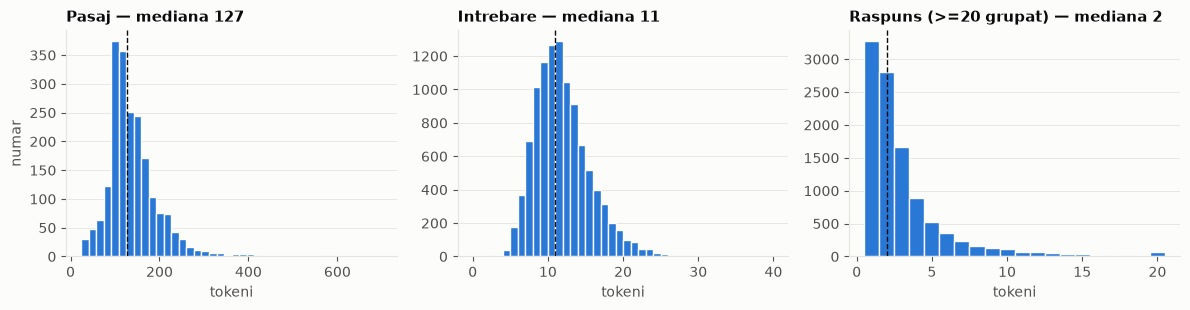

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
specs = [
    (para["context_len"], "Pasaj", 40),
    (df["question_len"], "Intrebare", np.arange(0, 41, 1)),
    (df["answer_len"].clip(upper=20), "Raspuns (>=20 grupat)", np.arange(0.5, 21.5, 1)),
]
for ax, (values, title, bins) in zip(axes, specs):
    ax.hist(values, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1)
    ax.axvline(values.median(), color=INK, linewidth=1, linestyle="--")
    ax.set_title(f"{title} — mediana {values.median():.0f}")
    ax.set_xlabel("tokeni")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("numar")
fig.tight_layout()
save(fig, "eda_lengths.png")

## 3. Lungime in tokeni BERT

Reader-ul primeste `[CLS] intrebare [SEP] pasaj [SEP]`. Daca perechea depaseste `max_length`, pasajul se imparte in ferestre cu suprapunere (stride).

median bert length: 163
p95 bert length:    299
max bert length:    819
pairs over 384 tokens: 1.73%


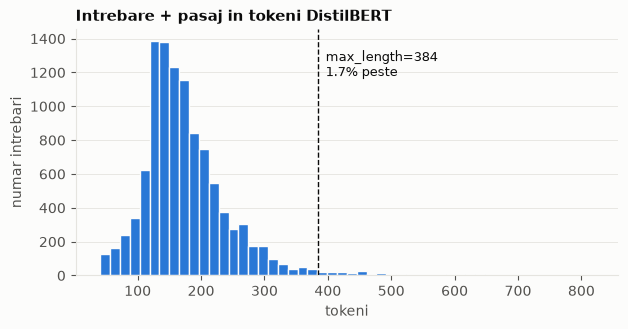

In [6]:
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased", cache_dir=CACHE_DIR)
encoded = tokenizer(df["question"].tolist(), df["context"].tolist(), verbose=False)
df["bert_len"] = [len(ids) for ids in encoded["input_ids"]]

over = (df["bert_len"] > MAX_LENGTH).mean()
print(f"median bert length: {df['bert_len'].median():.0f}")
print(f"p95 bert length:    {df['bert_len'].quantile(0.95):.0f}")
print(f"max bert length:    {df['bert_len'].max()}")
print(f"pairs over {MAX_LENGTH} tokens: {100 * over:.2f}%")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(df["bert_len"], bins=50, color=BLUE, edgecolor=SURFACE, linewidth=1)
ax.axvline(MAX_LENGTH, color=INK, linewidth=1, linestyle="--")
ax.text(MAX_LENGTH, ax.get_ylim()[1] * 0.92, f"  max_length={MAX_LENGTH}\n  {100 * over:.1f}% peste", color=INK, fontsize=9, va="top")
ax.set_title("Intrebare + pasaj in tokeni DistilBERT")
ax.set_xlabel("tokeni")
ax.set_ylabel("numar intrebari")
ax.grid(axis="x", visible=False)
save(fig, "eda_bert_length.png")

## 4. Tipuri de intrebari

Tipul intrebarii = primul cuvant interogativ (`question_type` din `src/qa/preprocess.py`, folosit si de baseline).

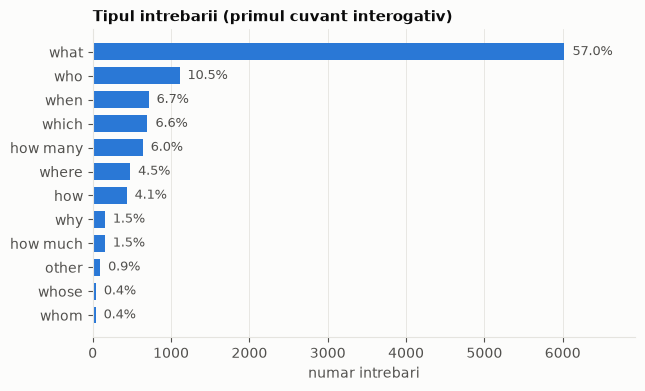

In [7]:
df["question_type"] = df["question"].apply(question_type)
qtype_counts = df["question_type"].value_counts()

fig, ax = plt.subplots(figsize=(7, 4))
hbar(ax, qtype_counts, len(df))
ax.set_title("Tipul intrebarii (primul cuvant interogativ)")
ax.set_xlabel("numar intrebari")
save(fig, "eda_question_types.png")

## 5. Tipul entitatii din raspuns (spaCy NER)

NER se ruleaza pe pasajul intreg (context complet, mai precis decat pe raspunsul izolat). Raspunsul primeste eticheta entitatii care acopera cel putin jumatate din el, altfel `NO_ENTITY`.

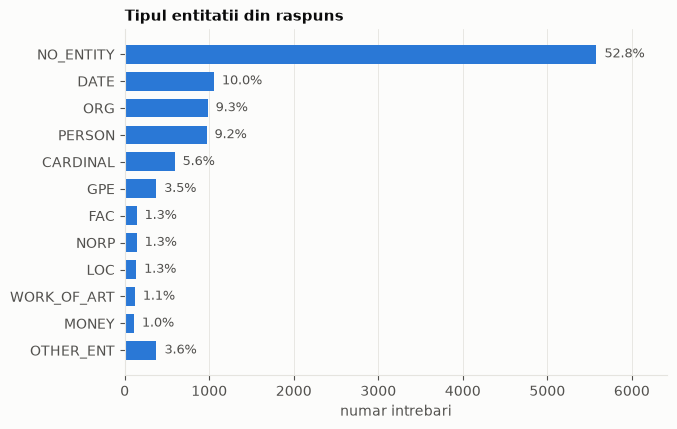

In [8]:
nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer", "tagger", "attribute_ruler"])
context_entities = {
    pid: [(ent.start_char, ent.end_char, ent.label_) for ent in doc.ents]
    for pid, doc in zip(para["paragraph_id"], nlp.pipe(para["text"], batch_size=64))
}


df["answer_entity"] = df.apply(
    lambda r: span_entity_label(r.answer_start, r.answer_start + len(r.answer), context_entities[r.paragraph_id]),
    axis=1,
)
entity_counts = df["answer_entity"].value_counts()
top_entities = entity_counts.head(11)
top_entities["OTHER_ENT"] = entity_counts.iloc[11:].sum()

fig, ax = plt.subplots(figsize=(7, 4.5))
hbar(ax, top_entities, len(df))
ax.set_title("Tipul entitatii din raspuns")
ax.set_xlabel("numar intrebari")
save(fig, "eda_answer_entities.png")

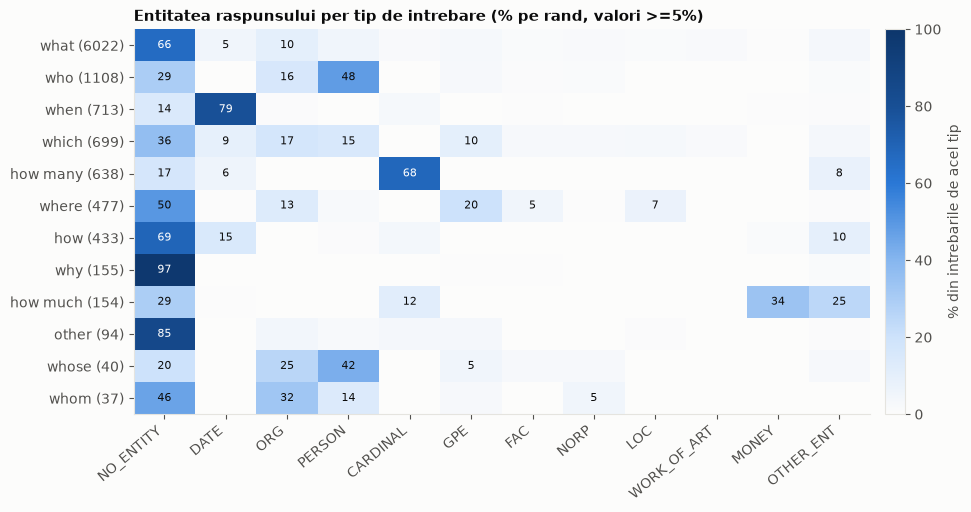

answer_entity,NO_ENTITY,DATE,ORG,PERSON,CARDINAL,GPE,FAC,NORP,LOC,WORK_OF_ART,MONEY,OTHER_ENT
question_type,,,,,,,,,,,,
what,65.7,5.4,9.8,4.8,1.6,2.9,1.3,1.7,1.3,1.7,0.8,3.2
who,29.4,0.1,15.9,48.1,0.0,2.3,1.0,1.4,0.4,0.1,0.0,1.4
when,14.2,79.2,1.0,0.1,2.8,0.1,0.7,0.1,0.0,0.3,0.4,1.0
which,36.2,9.0,16.9,14.9,0.1,9.9,2.6,2.6,2.9,1.6,0.0,3.4
how many,16.8,6.0,0.2,0.3,68.3,0.0,0.0,0.2,0.0,0.0,0.3,8.0
where,49.7,0.4,13.0,2.3,0.0,20.1,5.5,0.6,7.1,0.2,0.0,1.0
how,68.8,14.5,0.2,0.9,3.7,0.2,0.2,0.0,0.0,0.2,1.4,9.7
why,97.4,0.0,0.0,0.0,0.0,0.6,0.6,0.0,0.0,0.0,0.0,1.3
how much,29.2,0.6,0.0,0.0,11.7,0.0,0.0,0.0,0.0,0.0,33.8,24.7


In [9]:
row_order = qtype_counts.index.tolist()
col_order = [e for e in top_entities.index if e != "OTHER_ENT"]
entity_grouped = df["answer_entity"].where(df["answer_entity"].isin(col_order), "OTHER_ENT")
crosstab = pd.crosstab(df["question_type"], entity_grouped, normalize="index").reindex(
    index=row_order, columns=col_order + ["OTHER_ENT"], fill_value=0
) * 100

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(crosstab.values, cmap=SEQUENTIAL, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(crosstab.columns)), crosstab.columns, rotation=40, ha="right")
ax.set_yticks(range(len(crosstab.index)), [f"{q} ({qtype_counts[q]})" for q in crosstab.index])
for i in range(crosstab.shape[0]):
    for j in range(crosstab.shape[1]):
        value = crosstab.values[i, j]
        if value >= 5:
            ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if value >= 50 else INK)
ax.grid(False)
ax.set_title("Entitatea raspunsului per tip de intrebare (% pe rand, valori >=5%)")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="% din intrebarile de acel tip")
save(fig, "eda_qtype_entity_heatmap.png")
crosstab.round(1)

## 6. Pozitia raspunsului in pasaj

In a cata propozitie (NLTK) se afla raspunsul. Baseline-ul alege o propozitie, deci conteaza cat de concentrate sunt raspunsurile.

answers in first sentence: 32.4%
answers spanning 2+ sentences: 0.19%


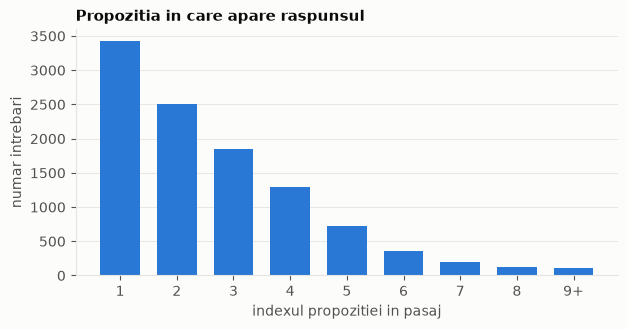

In [10]:
sentence_spans = {
    pid: list(sent_tokenizer.span_tokenize(text)) for pid, text in zip(para["paragraph_id"], para["text"])
}


def answer_sentence_index(row):
    for i, (start, end) in enumerate(sentence_spans[row.paragraph_id]):
        if start <= row.answer_start < end:
            return i
    return len(sentence_spans[row.paragraph_id]) - 1


df["answer_sentence"] = df.apply(answer_sentence_index, axis=1)
df["answer_rel_pos"] = df["answer_start"] / df["context"].str.len()
sentence_counts = df["answer_sentence"].clip(upper=8).value_counts().sort_index()

print(f"answers in first sentence: {100 * (df['answer_sentence'] == 0).mean():.1f}%")
print(f"answers spanning 2+ sentences: "
      f"{100 * df.apply(lambda r: any(s < r.answer_start + len(r.answer) <= e for s, e in sentence_spans[r.paragraph_id][r.answer_sentence + 1:]), axis=1).mean():.2f}%")

fig, ax = plt.subplots(figsize=(7, 3.2))
labels = [str(i + 1) for i in sentence_counts.index[:-1]] + ["9+"]
ax.bar(labels, sentence_counts.values, color=BLUE, width=0.7)
ax.set_title("Propozitia in care apare raspunsul")
ax.set_xlabel("indexul propozitiei in pasaj")
ax.set_ylabel("numar intrebari")
ax.grid(axis="x", visible=False)
save(fig, "eda_answer_sentence_position.png")

## 7. Corpusul pentru retriever

count    48.0
mean     43.1
std      18.6
min      21.0
25%      26.0
50%      43.5
75%      52.2
max      98.0
dtype: float64


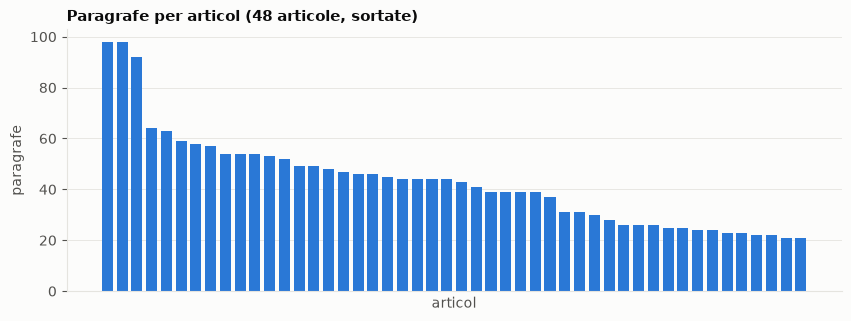

In [11]:
per_article = pd.Series({title: len(ids) for title, ids in articles.items()}).sort_values(ascending=False)
print(per_article.describe().round(1))

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(range(len(per_article)), per_article.values, color=BLUE, width=0.75)
ax.set_title("Paragrafe per articol (48 articole, sortate)")
ax.set_xlabel("articol")
ax.set_ylabel("paragrafe")
ax.set_xticks([])
ax.grid(axis="x", visible=False)
save(fig, "eda_paragraphs_per_article.png")

## 8. Sumar

In [12]:
summary = {
    "questions": len(df),
    "paragraphs": len(para),
    "articles": len(articles),
    "context_len_median": float(para["context_len"].median()),
    "question_len_median": float(df["question_len"].median()),
    "answer_len_median": float(df["answer_len"].median()),
    "answer_len_le_3_pct": round(float(100 * (df["answer_len"] <= 3).mean()), 1),
    "bert_len_over_max_pct": round(float(100 * over), 2),
    "question_types_pct": (100 * qtype_counts / len(df)).round(1).to_dict(),
    "answer_entity_pct": (100 * entity_counts / len(df)).round(1).head(12).to_dict(),
    "answer_in_first_sentence_pct": round(float(100 * (df["answer_sentence"] == 0).mean()), 1),
}
summary

{'questions': 10570,
 'paragraphs': 2067,
 'articles': 48,
 'context_len_median': 127.0,
 'question_len_median': 11.0,
 'answer_len_median': 2.0,
 'answer_len_le_3_pct': 73.3,
 'bert_len_over_max_pct': 1.73,
 'question_types_pct': {'what': 57.0,
  'who': 10.5,
  'when': 6.7,
  'which': 6.6,
  'how many': 6.0,
  'where': 4.5,
  'how': 4.1,
  'why': 1.5,
  'how much': 1.5,
  'other': 0.9,
  'whose': 0.4,
  'whom': 0.4},
 'answer_entity_pct': {'NO_ENTITY': 52.8,
  'DATE': 10.0,
  'ORG': 9.3,
  'PERSON': 9.2,
  'CARDINAL': 5.6,
  'GPE': 3.5,
  'FAC': 1.3,
  'NORP': 1.3,
  'LOC': 1.3,
  'WORK_OF_ART': 1.1,
  'MONEY': 1.0,
  'QUANTITY': 0.9},
 'answer_in_first_sentence_pct': 32.4}

## 9. Concluzii

- **Raspunsurile sunt scurte:** mediana 2 tokeni, 73% au cel mult 3 tokeni. Reader-ul trebuie sa prezica span-uri scurte, iar F1 pe tokeni e potrivit.
- **53% din intrebari au mai multe raspunsuri de referinta distincte**, deci EM/F1 se calculeaza ca maximul peste referinte.
- **Doar 1.7% din perechi depasesc 384 tokeni DistilBERT.** Sliding window-ul e necesar pentru corectitudine, dar afecteaza putine exemple.
- **Raspunsul aproape niciodata nu trece peste granita de propozitie (0.19%).** Pasul "alege propozitia" din baseline nu pierde raspunsuri prin constructie, insa doar 32% sunt in prima propozitie, deci alegerea propozitiei conteaza.
- **Tipul intrebarii prezice bine tipul entitatii** pentru: when -> DATE (79%), how many -> CARDINAL (68%), who -> PERSON (48%) + ORG (16%), how much -> MONEY (34%), where -> GPE/LOC/FAC (~33%) + ORG (13%). Acestea devin regulile din baseline.
- **"what" (57% din intrebari) are in 66% din cazuri raspuns fara entitate**, la fel why si how. Aici regulile NER nu ajuta, iar baseline-ul are nevoie de un fallback (de ex. noun chunk din propozitia aleasa). Ne asteptam ca baseline-ul sa fie slab tocmai pe aceste tipuri.
- **Corpusul pentru retriever:** 48 de articole cu 21-98 de paragrafe fiecare. Paragrafele din acelasi articol sunt similare lexical, ceea ce face retrieval-ul la nivel de paragraf mai dificil decat la nivel de articol.